In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Global plotting style
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

df = pd.read_csv('../data/processed/dataset.csv', low_memory=False)
print(f"Loaded dataset.csv: {df.shape[0]:,} records x {df.shape[1]} columns")

Loaded dataset.csv: 129,673 records x 41 columns


---
## Dataset Inspection, Target Distributions, and Missingness

We first examine the schema, feature groupings (Model A pre-strike numerical and categorical/ordinal predictors, Model B post-inspection `STR_*`/`ING_*` indicators, and target labels `y3` and `y_bin`), summary statistics, class frequencies, and missing-value rates overall and stratified by target class.

In [2]:
num_cols = ['HEIGHT', 'SPEED', 'DISTANCE', 'INCIDENT_MONTH', 'BodyMass', 'ImpactEnergy', 'log_ImpactEnergy']
cat_ord_cols = [
    'AC_CLASS', 'AC_MASS', 'NUM_ENGS', 'TYPE_ENG', 'PHASE_OF_FLIGHT',
    'TIME_OF_DAY', 'FAAREGION', 'SKY', 'PRECIPITATION',
    'SIZE', 'NUM_SEEN', 'NUM_STRUCK', 'WARNED', 'SpeciesGroup'
]
borderline_cols = [c for c in df.columns if c.startswith(('STR_', 'ING_'))]
target_cols = ['y3', 'y_bin']

print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_ord_cols)}): {cat_ord_cols}")
print(f"Borderline Model B strike/ingestion features ({len(borderline_cols)}): {len(borderline_cols)} binary indicators")
print(f"Target columns ({len(target_cols)}): {target_cols}")

# Schema & missingness overview table
schema_df = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing_count': df.isna().sum(),
    'missing_pct': df.isna().mean() * 100,
    'n_unique': df.nunique(dropna=True)
})
print("\n--- Feature Schema & Overall Missingness ---")
print(schema_df.to_string())

Numerical features (7): ['HEIGHT', 'SPEED', 'DISTANCE', 'INCIDENT_MONTH', 'BodyMass', 'ImpactEnergy', 'log_ImpactEnergy']
Categorical features (14): ['AC_CLASS', 'AC_MASS', 'NUM_ENGS', 'TYPE_ENG', 'PHASE_OF_FLIGHT', 'TIME_OF_DAY', 'FAAREGION', 'SKY', 'PRECIPITATION', 'SIZE', 'NUM_SEEN', 'NUM_STRUCK', 'WARNED', 'SpeciesGroup']
Borderline Model B strike/ingestion features (18): 18 binary indicators
Target columns (2): ['y3', 'y_bin']

--- Feature Schema & Overall Missingness ---
                    dtype  non_null  missing_count  missing_pct  n_unique
HEIGHT            float64     86501          43172       33.293       562
SPEED             float64     56005          73668       56.811       269
DISTANCE          float64     71463          58210       44.890       225
INCIDENT_MONTH      int64    129673              0        0.000        12
AC_CLASS              str    128872            801        0.618         3
AC_MASS           float64    128869            804        0.620         5


In [3]:
# Target variable distributions (y3 and y_bin)
y3_labels = {0.0: '0: None (N)', 1.0: '1: Minor (M)', 2.0: '2: Substantial/Destroyed (S/D)'}
y3_counts = df['y3'].map(y3_labels).fillna('Missing (M?: Undetermined Damage)').value_counts()
y3_summary = pd.DataFrame({
    'Count': y3_counts,
    'Share_All (%)': y3_counts / len(df) * 100,
})
valid_y3_total = df['y3'].notna().sum()
y3_summary['Share_Valid_y3 (%)'] = [
    (c / valid_y3_total * 100) if idx != 'Missing (M?: Undetermined Damage)' else np.nan
    for idx, c in y3_counts.items()
]
print("--- Three-Class Target (y3) Distribution ---")
print(y3_summary.to_string())

ybin_labels = {0: '0: Not Damaged (N)', 1: '1: Damaged (M, M?, S, D)'}
ybin_counts = df['y_bin'].map(ybin_labels).value_counts()
ybin_summary = pd.DataFrame({
    'Count': ybin_counts,
    'Share_All (%)': ybin_counts / len(df) * 100
})
print("\n--- Binary Target (y_bin) Distribution ---")
print(ybin_summary.to_string())

print("\n--- Summary Statistics: Numerical Features ---")
desc_num = df[num_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_num['missing_%'] = df[num_cols].isna().mean() * 100
print(desc_num[['count', 'missing_%', 'mean', 'std', 'min', '25%', '50%', '75%', '95%', '99%', 'max']].to_string())

--- Three-Class Target (y3) Distribution ---
                                    Count  Share_All (%)  Share_Valid_y3 (%)
y3                                                                          
0: None (N)                        119882         92.449              96.566
Missing (M?: Undetermined Damage)    5528          4.263                 NaN
1: Minor (M)                         2799          2.159               2.255
2: Substantial/Destroyed (S/D)       1464          1.129               1.179

--- Binary Target (y_bin) Distribution ---
                           Count  Share_All (%)
y_bin                                          
0: Not Damaged (N)        119882         92.449
1: Damaged (M, M?, S, D)    9791          7.551

--- Summary Statistics: Numerical Features ---
                       count  missing_%      mean       std   min     25%     50%       75%       95%        99%        max
HEIGHT            86,501.000     33.293   976.577 1,896.311 0.000   0.000 100.000 1,0

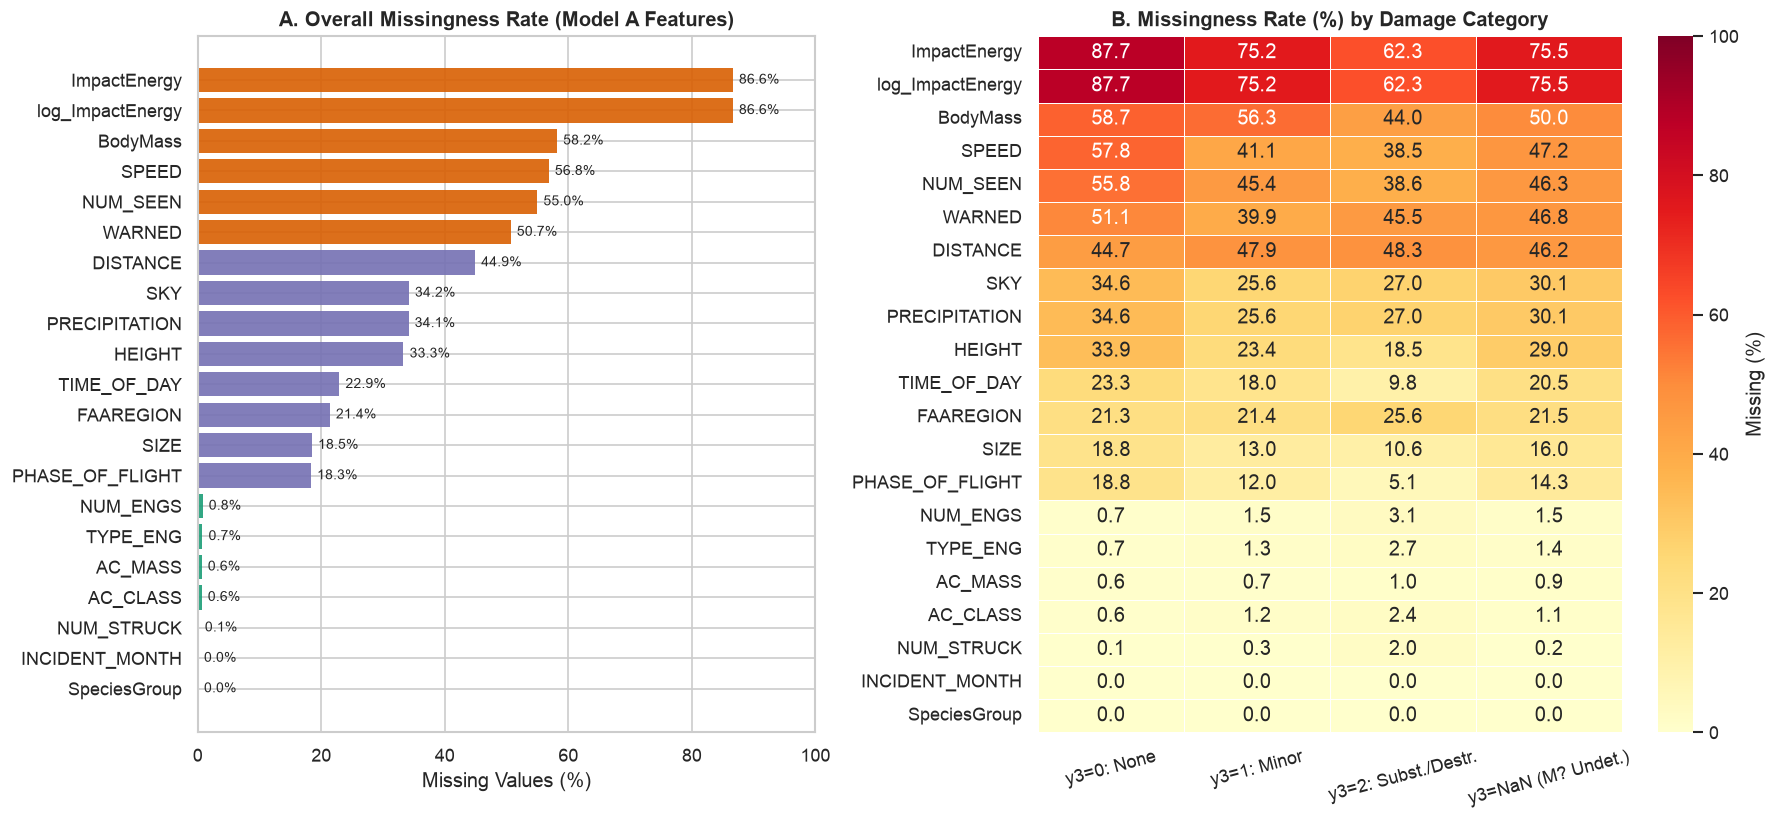

In [4]:
# Visualize missingness overall and stratified by target class
model_a_cols = num_cols + cat_ord_cols
miss_overall = (df[model_a_cols].isna().mean() * 100).sort_values(ascending=True)

df_plot_miss = df.copy()
df_plot_miss['Target_Group'] = df_plot_miss['y3'].map({
    0.0: 'y3=0: None',
    1.0: 'y3=1: Minor',
    2.0: 'y3=2: Subst./Destr.'
}).fillna('y3=NaN (M? Undet.)')

miss_by_class = (
    df_plot_miss.groupby('Target_Group')[model_a_cols]
    .apply(lambda g: g.isna().mean() * 100)
    .T
    .loc[miss_overall.index[::-1], ['y3=0: None', 'y3=1: Minor', 'y3=2: Subst./Destr.', 'y3=NaN (M? Undet.)']]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.1, 1.3]})

# Panel A: Horizontal bar chart of overall missingness
colors_bar = ['#d95f02' if v > 50 else '#1b9e77' if v < 10 else '#7570b3' for v in miss_overall.values]
axes[0].barh(miss_overall.index, miss_overall.values, color=colors_bar, edgecolor='none', alpha=0.9)
for i, v in enumerate(miss_overall.values):
    axes[0].text(v + 1.0, i, f"{v:.1f}%", va='center', fontsize=8.5)
axes[0].set_xlim(0, 100)
axes[0].set_xlabel('Missing Values (%)')
axes[0].set_title('A. Overall Missingness Rate (Model A Features)')

# Panel B: Heatmap of missingness (%) by target class
sns.heatmap(
    miss_by_class, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Missing (%)'},
    linewidths=0.5, ax=axes[1], vmin=0, vmax=100
)
axes[1].set_title('B. Missingness Rate (%) by Damage Category')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
fig.savefig('../plots/eda_missingness.png', dpi=200, bbox_inches='tight')
plt.show()


### Key Finding
* **Sample Size & Class Imbalance**: Out of **129,673** strike records, **124,145** have a valid three-class label `y3`: **96.57%** (`119,882`) are `None` (`y3 = 0`), **2.25%** (`2,799`) are `Minor` (`y3 = 1`), and **1.18%** (`1,464`) are `Substantial/Destroyed` (`y3 = 2`). The remaining **5,528** records (`4.26%` of total) correspond to `DAMAGE = M?` (damaged, extent undetermined), which are excluded from the three-class task (`y3 = NaN`) but included as positives in the binary task (`y_bin = 1`: `9,791` damaged vs. `119,882` undamaged, or `7.55%` positive rate).
* **Feature Missingness Tiers**:
  * **Complete / Near-Complete (`< 2%` missing)**: `INCIDENT_MONTH` (`0%`), `SpeciesGroup` (`0%`, though `'Unknown'` encodes unmatched species), all 18 post-inspection `STR_*`/`ING_*` indicators (`0%`), `NUM_STRUCK` (`0.14%`), `AC_CLASS` (`0.62%`), `AC_MASS` (`0.62%`), `TYPE_ENG` (`0.74%`), and `NUM_ENGS` (`0.77%`).
  * **Moderate Missingness (`18%–45%`)**: `PHASE_OF_FLIGHT` (`18.3%`), `SIZE` (`18.5%`), `FAAREGION` (`21.4%`), `TIME_OF_DAY` (`22.9%`), `HEIGHT` (`33.3%`), `PRECIPITATION` (`34.1%`), `SKY` (`34.2%`), and `DISTANCE` (`44.9%`).
  * **High Missingness (`> 50%`)**: `WARNED` (`50.7%`), `NUM_SEEN` (`55.0%`), `SPEED` (`56.8%`), `BodyMass` (`58.2%`, due to generic/unidentified species reports), and `ImpactEnergy` / `log_ImpactEnergy` (`86.6%`, missing whenever either `SPEED` or `BodyMass` is missing).

---
## Numerical Distributions, Skewness, Extreme Values, and Plausibility Checks

Next, we inspect the distributions, boxplots, and skewness of all numerical predictors (`HEIGHT`, `SPEED`, `DISTANCE`, `INCIDENT_MONTH`, `BodyMass`, `ImpactEnergy`, and `log_ImpactEnergy`), check for physically implausible entries (overall and stratified by aircraft class and flight phase).

In [5]:
# Skewness and quantile diagnostics
skew_table = pd.DataFrame({
    'N_valid': df[num_cols].notna().sum(),
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Std': df[num_cols].std(),
    'IQR': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    'Skewness': df[num_cols].skew(),
    'Min': df[num_cols].min(),
    'P99': df[num_cols].quantile(0.99),
    'Max': df[num_cols].max()
})
print("--- Skewness, Dispersion, and Extreme Quantiles ---")
print(skew_table.to_string())

# Physical plausibility & cross-variable consistency checks
print("\n--- Physical Plausibility & Cross-Variable Checks ---")
checks = {
    'Negative HEIGHT, SPEED, DISTANCE, or BodyMass': (
        (df['HEIGHT'] < 0) | (df['SPEED'] < 0) | (df['DISTANCE'] < 0) | (df['BodyMass'] <= 0)
    ).sum(),
    'HEIGHT > 45,000 ft (above commercial ceiling)': (df['HEIGHT'] > 45000).sum(),
    'SPEED > 600 knots (transonic/supersonic anomaly)': (df['SPEED'] > 600).sum(),
    'Take-off Run or Landing Roll with HEIGHT > 500 ft': (
        df['PHASE_OF_FLIGHT'].isin(['Take-off Run', 'Landing Roll']) & (df['HEIGHT'] > 500)
    ).sum(),
    'Take-off Run or Landing Roll with HEIGHT > 0 ft': (
        df['PHASE_OF_FLIGHT'].isin(['Take-off Run', 'Landing Roll']) & (df['HEIGHT'] > 0)
    ).sum(),
    'Climb, Approach, or En Route with SPEED == 0 kt': (
        df['PHASE_OF_FLIGHT'].isin(['Climb', 'Approach', 'En Route']) & (df['SPEED'] == 0)
    ).sum(),
    'Helicopter with SPEED > 220 kt or HEIGHT > 15,000 ft': (
        (df['AC_CLASS'] == 'helicopter') & ((df['SPEED'] > 220) | (df['HEIGHT'] > 15000))
    ).sum(),
    'Piston aircraft with SPEED > 250 kt or HEIGHT > 20,000 ft': (
        (df['TYPE_ENG'] == 'piston') & ((df['SPEED'] > 250) | (df['HEIGHT'] > 20000))
    ).sum(),
}
for desc, count in checks.items():
    print(f"  {desc:<56}: {count}")

print("\nMax HEIGHT and SPEED by AC_CLASS:")
print(df.groupby('AC_CLASS')[['HEIGHT', 'SPEED']].agg(['count', 'median', 'max']))

--- Skewness, Dispersion, and Extreme Quantiles ---
                  N_valid      Mean  Median       Std       IQR  Skewness   Min        P99        Max
HEIGHT              86501   976.577 100.000 1,896.311 1,000.000     3.339 0.000  9,200.000 32,000.000
SPEED               56005   144.602 140.000    46.933    45.000     0.541 0.000    250.000    400.000
DISTANCE            71463     2.090   0.000     5.426     1.000     4.810 0.000     25.000     99.000
INCIDENT_MONTH     129673     7.311   8.000     2.767     5.000    -0.396 1.000     12.000     12.000
BodyMass            54268     0.309   0.077     0.701     0.098     4.241 0.003      3.428     10.682
ImpactEnergy        17360 1,213.796 200.552 2,990.783   857.021     5.952 0.000 14,626.324 52,748.577
log_ImpactEnergy    17360     5.535   5.306     1.746     2.687     0.411 0.000      9.591     10.873

--- Physical Plausibility & Cross-Variable Checks ---
  Negative HEIGHT, SPEED, DISTANCE, or BodyMass           : 0
  HEIGHT > 45,0

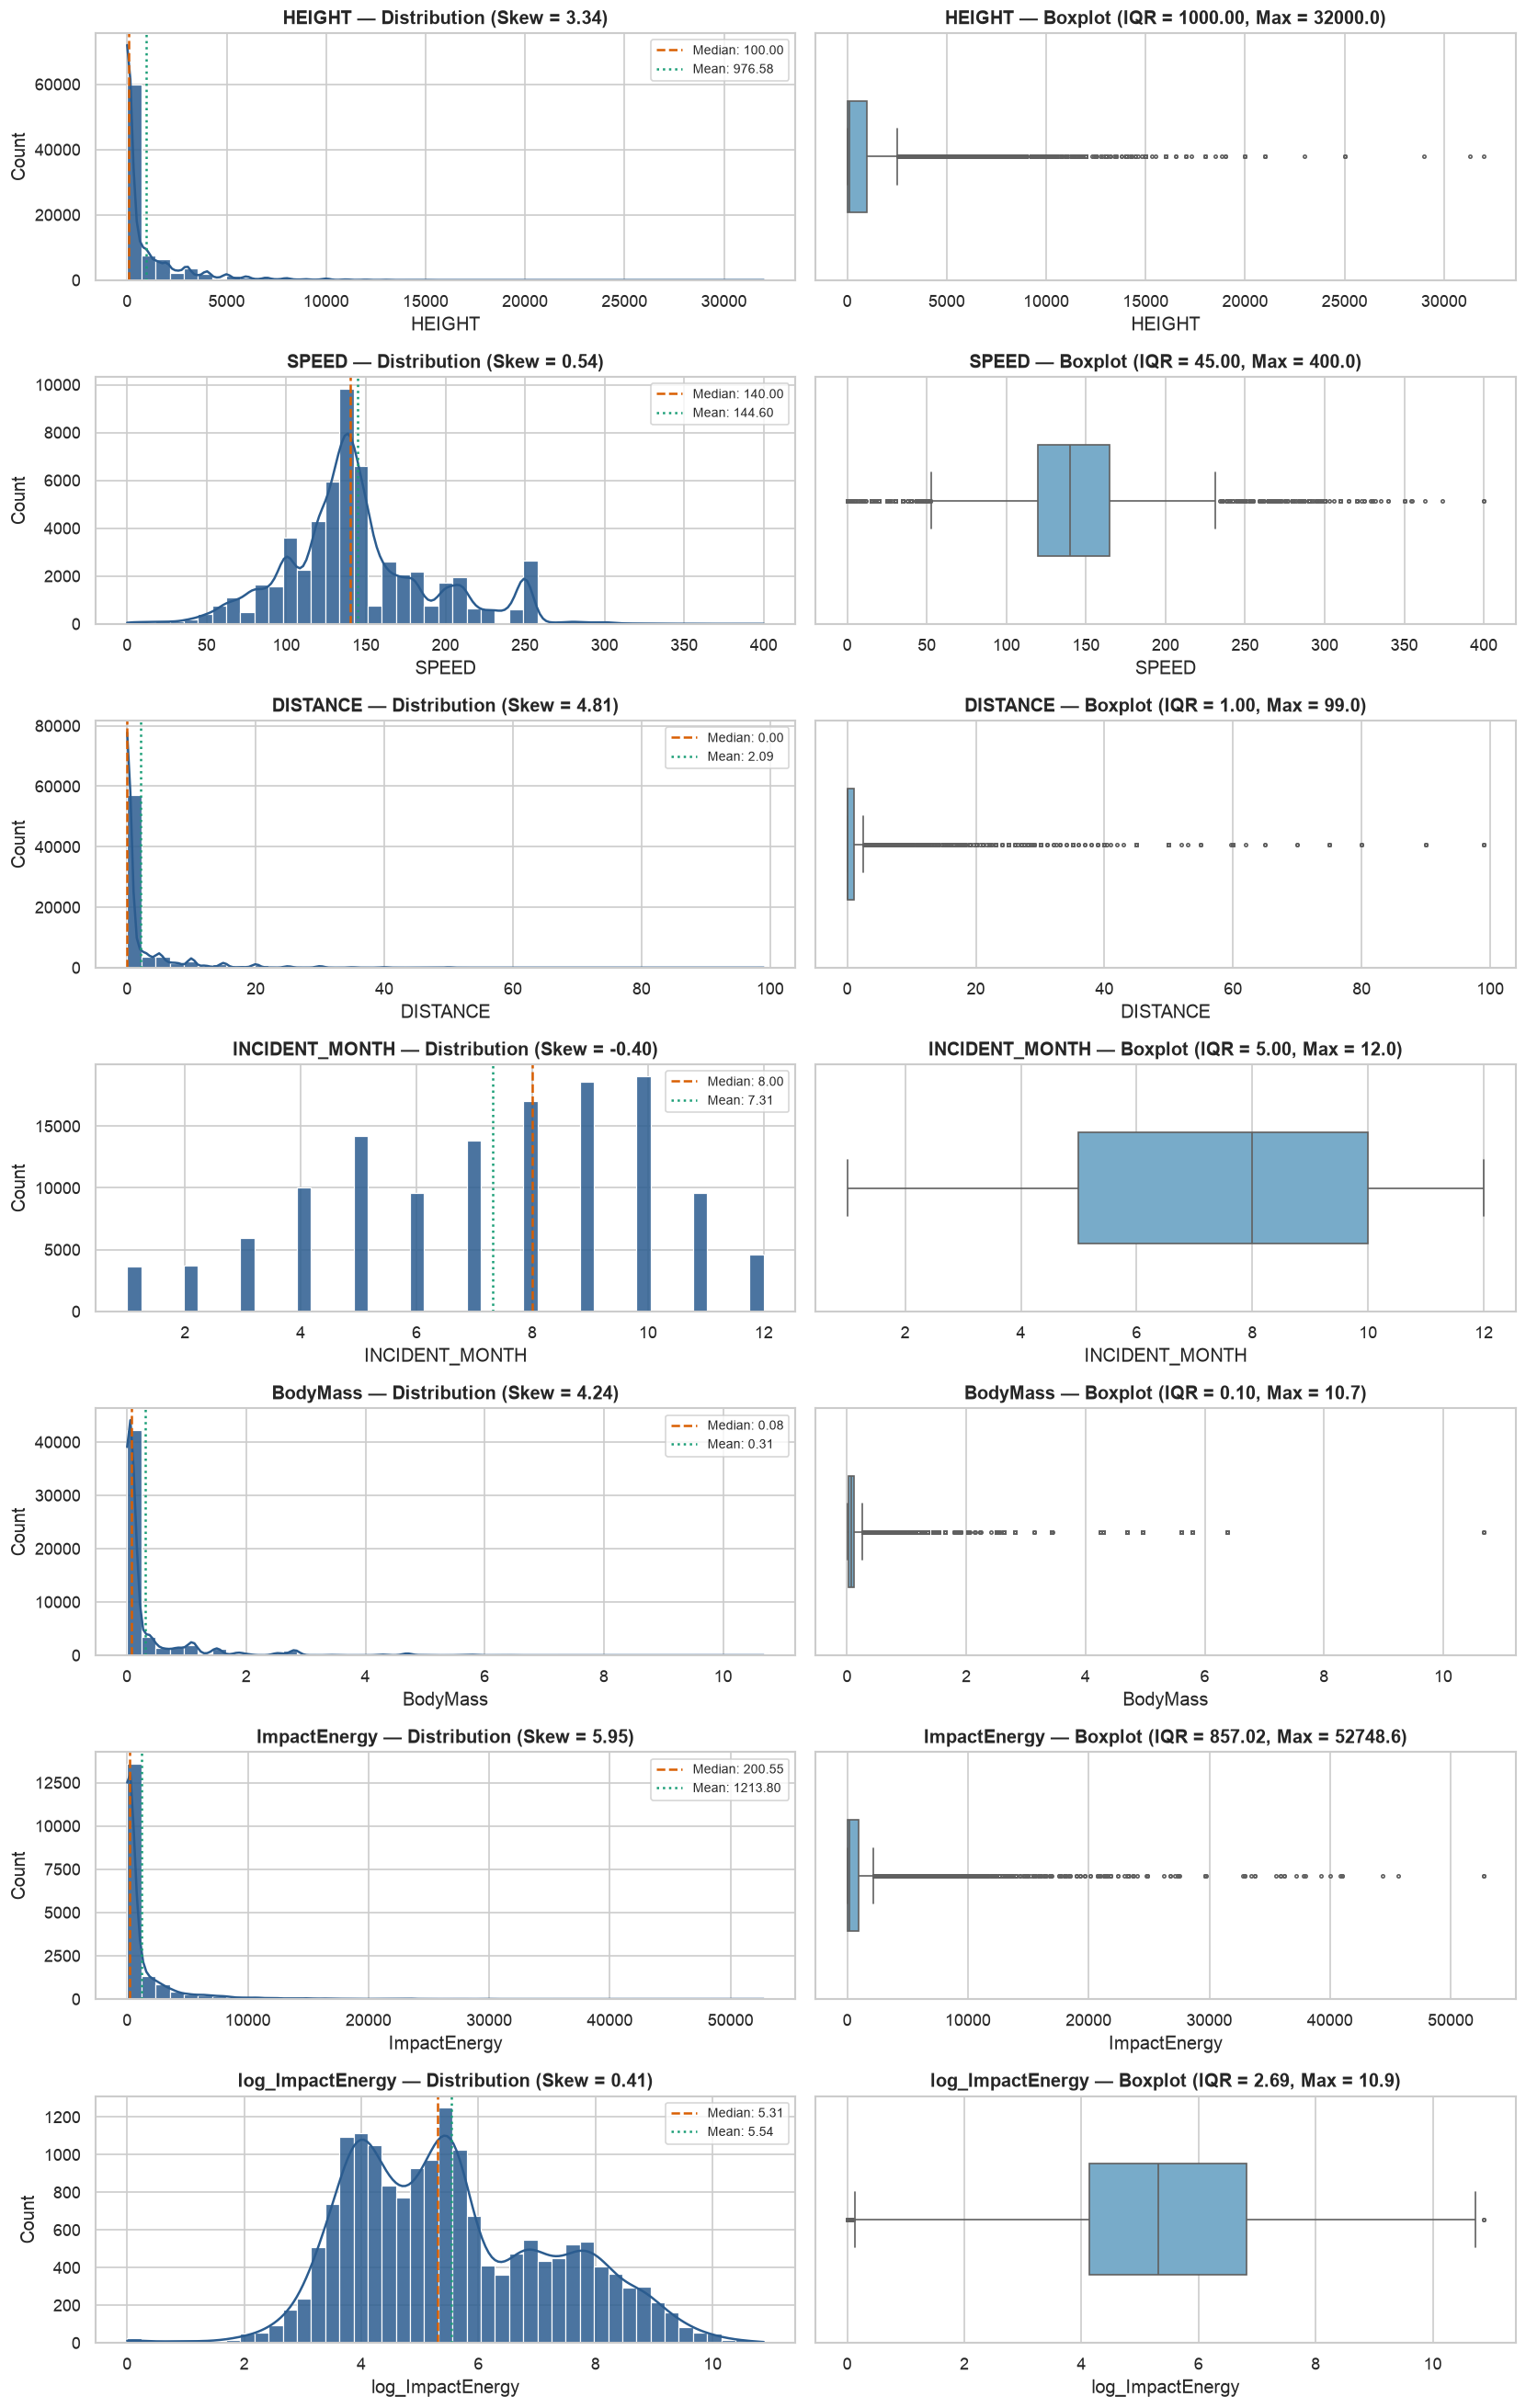

In [6]:
# Distributions (Histograms + KDE) and Boxplots of Numerical Variables
plot_vars = ['HEIGHT', 'SPEED', 'DISTANCE', 'INCIDENT_MONTH', 'BodyMass', 'ImpactEnergy', 'log_ImpactEnergy']
fig, axes = plt.subplots(len(plot_vars), 2, figsize=(14, 22))

for idx, col in enumerate(plot_vars):
    s = df[col].dropna()
    ax_hist, ax_box = axes[idx, 0], axes[idx, 1]

    # Histogram + KDE (use log-scale x-axis hint via annotations for heavy tails)
    sns.histplot(s, bins=45, kde=(col != 'INCIDENT_MONTH'), ax=ax_hist, color='#2b5c8f', edgecolor='white', alpha=0.85)
    ax_hist.axvline(s.median(), color='#d95f02', linestyle='--', linewidth=1.5, label=f'Median: {s.median():.2f}')
    ax_hist.axvline(s.mean(), color='#1b9e77', linestyle=':', linewidth=1.5, label=f'Mean: {s.mean():.2f}')
    ax_hist.set_title(f"{col} — Distribution (Skew = {s.skew():.2f})")
    ax_hist.set_ylabel('Count')
    ax_hist.legend(fontsize=8.5, loc='upper right')

    # Horizontal Boxplot
    sns.boxplot(x=s, ax=ax_box, color='#6baed6', fliersize=2, width=0.45)
    ax_box.set_title(f"{col} — Boxplot (IQR = {s.quantile(0.75) - s.quantile(0.25):.2f}, Max = {s.max():.1f})")
    ax_box.set_xlabel(col)

plt.tight_layout()
fig.savefig('../plots/eda_distributions.png', dpi=200, bbox_inches='tight')
plt.show()


### Key Findings & Justification of Transformations / Outlier Handling 
* **Severe Right Skewness**:
  * `ImpactEnergy` (`skew = 5.95`, median `200.6 J`, 99th percentile `14,626 J`, max `52,749 J`), `DISTANCE` (`skew = 4.81`, median `0 NM`, max `99 NM`), `BodyMass` (`skew = 4.24`, median `0.077 kg`, max `10.68 kg`), and `HEIGHT` (`skew = 3.34`, median `100 ft`, max `32,000 ft`) exhibit strong positive skewness because most strikes occur near the airport environment at low altitude and involve small passerines or gulls, whereas rare high-speed strikes with large waterfowl or raptors generate orders-of-magnitude higher kinetic energy.
  * By contrast, `SPEED` (`skew = 0.54`, mean `144.6 kt`, median `140.0 kt`) is roughly symmetric around typical approach/climb airspeeds, and `INCIDENT_MONTH` (`skew = -0.40`) peaks during late-summer/autumn migration (July–October).
* **Justification for Transformations**:
  * `log_ImpactEnergy` (`log1p(ImpactEnergy)`) reduces skewness from **5.95** down to **0.41**, making it nearly symmetric and well-suited for linear/logistic models and PCA.
  * Similarly, `log1p(HEIGHT)`, `log1p(DISTANCE)`, and `log1p(BodyMass)` are strong candidates for linear classifiers (logistic regression), whereas tree-based models (decision trees, random forests) are invariant to monotonic transformations.
* **Outlier & Plausibility Assessment**:
  * `dataset.csv` has already been sanitized against impossible physical records: there are **0** negative values, **0** heights above `32,000 ft`, **0** airspeeds above `400 kt`, and helicopter (`max HEIGHT = 11,000 ft`, `max SPEED = 200 kt`) and piston-aircraft (`max HEIGHT = 9,500 ft`, `max SPEED = 210 kt`) records lie well within realistic flight envelopes.
  * Because extreme upper values (e.g., `HEIGHT = 32,000 ft` during en-route cruise or `BodyMass = 10.68 kg` for large waterfowl/pelicans) represent genuine high-energy operational events rather than sensor errors, **winsorizing or dropping upper extremes is not recommended**, as those tail events carry critical signal for `Substantial/Destroyed` damage.

---
## Numerical Indicators Across Damage Classes

We compare `HEIGHT`, `SPEED`, `DISTANCE`, `BodyMass`, `ImpactEnergy`, `log_ImpactEnergy`, and `INCIDENT_MONTH` across `y3` (`0: None`, `1: Minor`, `2: Substantial/Destroyed`) and `y_bin` (`0: Not Damaged`, `1: Damaged`).

In [7]:
# Descriptive statistics across y3 classes (and M? undetermined)
df_y3 = df.copy()
df_y3['Damage_Class'] = df_y3['y3'].map({
    0.0: '0: None',
    1.0: '1: Minor',
    2.0: '2: Subst./Destr.'
}).fillna('M?: Undetermined')

class_order = ['0: None', '1: Minor', '2: Subst./Destr.', 'M?: Undetermined']
stats_rows = []
for col in ['HEIGHT', 'SPEED', 'DISTANCE', 'BodyMass', 'ImpactEnergy', 'log_ImpactEnergy', 'INCIDENT_MONTH']:
    grp = df_y3.groupby('Damage_Class')[col]
    summary = pd.DataFrame({
        'Feature': col,
        'N': grp.count(),
        'Mean': grp.mean(),
        'SD': grp.std(),
        'Median': grp.median(),
        'IQR': grp.quantile(0.75) - grp.quantile(0.25)
    }).reindex(class_order)
    stats_rows.append(summary)

comp_table = pd.concat(stats_rows).reset_index()
print("--- Numerical Indicators by Damage Category ---")
print(comp_table.to_string(index=False))


--- Numerical Indicators by Damage Category ---
    Damage_Class          Feature      N      Mean        SD    Median       IQR
         0: None           HEIGHT  79238   928.151 1,838.209    50.000 1,000.000
        1: Minor           HEIGHT   2144 1,381.646 2,254.019   500.000 1,690.000
2: Subst./Destr.           HEIGHT   1193 1,381.622 2,377.073   600.000 1,600.000
M?: Undetermined           HEIGHT   3926 1,609.675 2,440.666   700.000 1,990.000
         0: None            SPEED  50538   144.872    45.882   140.000    40.000
        1: Minor            SPEED   1649   139.271    54.489   130.000    70.000
2: Subst./Destr.            SPEED    900   139.666    54.635   130.000    70.000
M?: Undetermined            SPEED   2918   144.470    56.534   140.000    80.000
         0: None         DISTANCE  66271     1.984     5.262     0.000     1.000
        1: Minor         DISTANCE   1459     3.158     7.069     0.000     3.000
2: Subst./Destr.         DISTANCE    757     3.125     7.258 

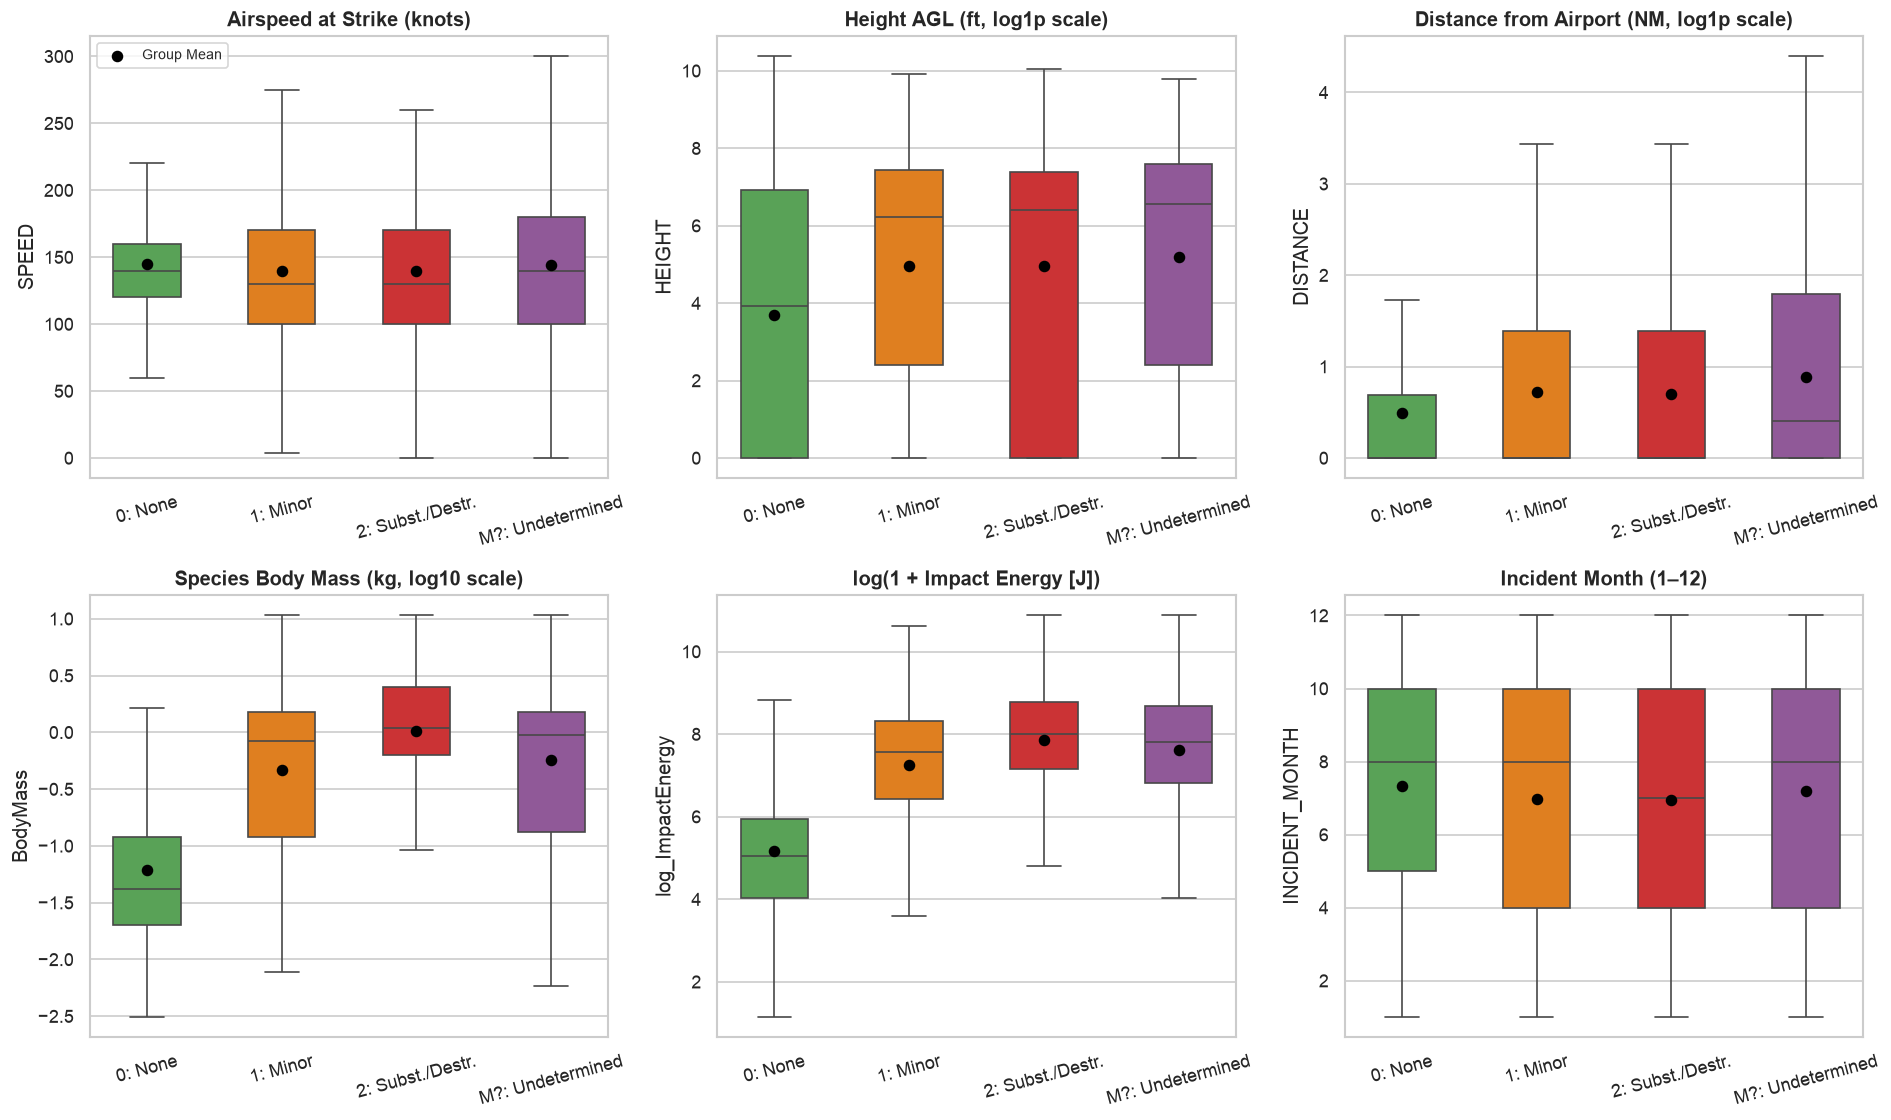

In [8]:
# Boxplots & Violin/Point comparisons of key physical variables across y3
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
palette_y3 = ['#4daf4a', '#ff7f00', '#e41a1c', '#984ea3']

# Row 1: Raw / Log-scaled continuous variables
specs = [
    ('SPEED', 'Airspeed at Strike (knots)', False),
    ('HEIGHT', 'Height AGL (ft, log1p scale)', True),
    ('DISTANCE', 'Distance from Airport (NM, log1p scale)', True),
    ('BodyMass', 'Species Body Mass (kg, log10 scale)', 'log10'),
    ('log_ImpactEnergy', 'log(1 + Impact Energy [J])', False),
    ('INCIDENT_MONTH', 'Incident Month (1–12)', False)
]

for ax, (col, title, scale_mode) in zip(axes.flat, specs):
    plot_d = df_y3[['Damage_Class', col]].dropna().copy()
    if scale_mode is True:
        plot_d[col] = np.log1p(plot_d[col])
    elif scale_mode == 'log10':
        plot_d[col] = np.log10(plot_d[col])

    sns.boxplot(
        data=plot_d, x='Damage_Class', y=col, order=class_order,
        palette=palette_y3, ax=ax, showfliers=False, width=0.5
    )
    # Overlay group means
    means = plot_d.groupby('Damage_Class')[col].mean().reindex(class_order)
    ax.scatter(range(len(class_order)), means.values, color='black', zorder=5, s=35, label='Group Mean')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
    if ax == axes[0, 0]:
        ax.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
fig.savefig('../plots/eda_numeric_by_class.png', dpi=200, bbox_inches='tight')
plt.show()


### Physical Interpretation of Numerical Patterns
* **Monotonic Scaling with Impact Physics**: Across `y3 = 0 (None)`, `y3 = 1 (Minor)`, and `y3 = 2 (Substantial/Destroyed)`, median indicators increase monotonically:
  * **Airspeed (`SPEED`)**: Median speed rises from **140.0 kt** (`None`) to **150.0 kt** (`Minor`) and **150.0 kt** (`Substantial/Destroyed`), while mean speed increases from **143.9 kt** to **153.2 kt** and **152.7 kt**. Because kinetic energy scales with the square of velocity ($E = \frac{1}{2}mv^2$), higher airspeeds are associated with substantially greater momentum transfer at impact.
  * **Species Body Mass (`BodyMass`)**: Median struck-species mass rises by more than an order of magnitude—from **0.072 kg** (`None`) to **0.713 kg** (`Minor`) and **1.147 kg** (`Substantial/Destroyed`).
  * **Kinetic Impact Energy (`ImpactEnergy` / `log_ImpactEnergy`)**: Combining mass and squared speed produces the sharpest class separation: median `ImpactEnergy` rises from **186.6 J** (`None`, `log_ImpactEnergy = 5.23`) to **2,043.6 J** (`Minor`, `log_ImpactEnergy = 7.62`) and **3,190.7 J** (`Substantial/Destroyed`, `log_ImpactEnergy = 8.07`).
  * **Altitude (`HEIGHT`) & Distance (`DISTANCE`)**: Undamaged strikes cluster near the runway surface (median `HEIGHT = 50 ft`, `DISTANCE = 0 NM`), whereas damaging strikes occur higher and farther along climb/approach corridors (median `HEIGHT = 800 ft` for `Minor` and `500 ft` for `Substantial/Destroyed`), where aircraft speeds are higher and flocking migratory birds are encountered.
  * **Undetermined Damage (`M?`)**: Records labeled `M?` have median `BodyMass = 0.351 kg` and median `ImpactEnergy = 984.9 J`—intermediate between `None` and confirmed `Minor` damage—consistent with reports where minor/moderate damage was noted upon arrival without a full engineering classification.


---
## Correlations and Redundancy Among Numerical Predictors

We compute both **Pearson** (linear) and **Spearman** (rank/monotonic) correlation matrices across all numerical features (plus ordinal `AC_MASS` and `NUM_ENGS` for context) to identify redundant features and collinear pairs.

--- Pearson Correlation Matrix ---
                  HEIGHT  SPEED  DISTANCE  INCIDENT_MONTH  BodyMass  ImpactEnergy  log_ImpactEnergy  AC_MASS  NUM_ENGS
HEIGHT             1.000  0.699     0.838           0.039     0.052         0.224             0.179    0.070     0.036
SPEED              0.699  1.000     0.649           0.036    -0.036         0.281             0.295    0.470     0.327
DISTANCE           0.838  0.649     1.000           0.036     0.059         0.230             0.165    0.099     0.053
INCIDENT_MONTH     0.039  0.036     0.036           1.000    -0.068        -0.025            -0.049    0.017     0.001
BodyMass           0.052 -0.036     0.059          -0.068     1.000         0.763             0.723   -0.208    -0.108
ImpactEnergy       0.224  0.281     0.230          -0.025     0.763         1.000             0.669   -0.002     0.020
log_ImpactEnergy   0.179  0.295     0.165          -0.049     0.723         0.669             1.000   -0.014     0.003
AC_MASS      

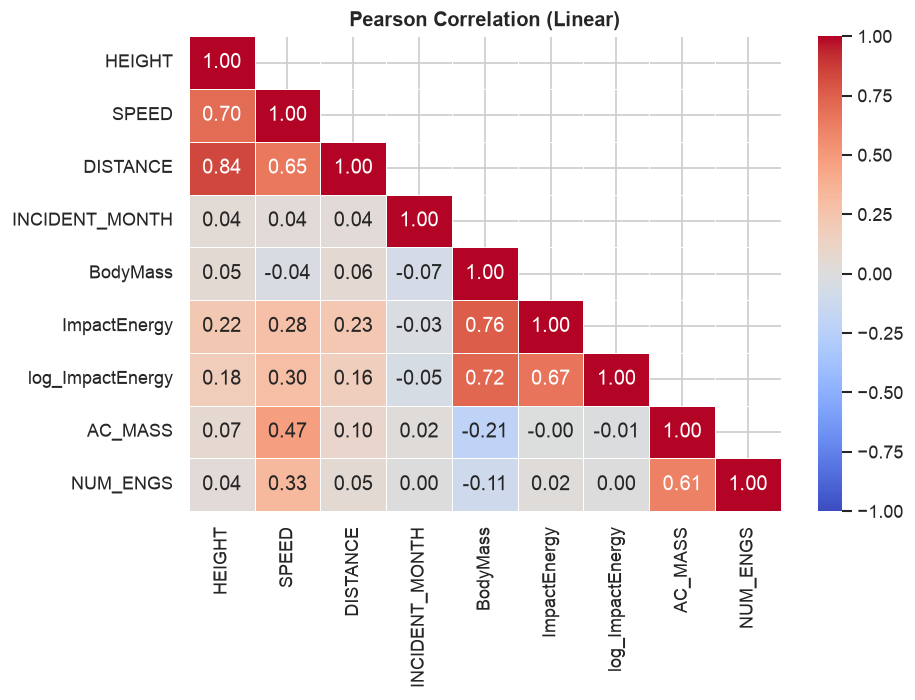

In [9]:
corr_cols = ['HEIGHT', 'SPEED', 'DISTANCE', 'INCIDENT_MONTH', 'BodyMass', 'ImpactEnergy', 'log_ImpactEnergy', 'AC_MASS', 'NUM_ENGS']
pearson_corr = df[corr_cols].corr(method='pearson')

print("--- Pearson Correlation Matrix ---")
print(pearson_corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(pearson_corr, dtype=bool), k=1)

sns.heatmap(pearson_corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Pearson Correlation (Linear)')

plt.tight_layout()
fig.savefig('../plots/eda_correlation.png', dpi=200, bbox_inches='tight')
plt.show()


In [10]:
# Joint relationship among HEIGHT, SPEED, and PHASE_OF_FLIGHT
top_phases = ['Landing Roll', 'Take-off Run', 'Approach', 'Climb', 'Descent', 'En Route']
phase_kinematics = (
    df[df['PHASE_OF_FLIGHT'].isin(top_phases)]
    .groupby('PHASE_OF_FLIGHT')[['HEIGHT', 'SPEED', 'DISTANCE']]
    .agg(['count', 'median', 'mean'])
    .reindex(top_phases)
)
print("--- Kinematics (HEIGHT, SPEED, DISTANCE) by Major Phase of Flight ---")
print(phase_kinematics.to_string())

--- Kinematics (HEIGHT, SPEED, DISTANCE) by Major Phase of Flight ---
                HEIGHT                       SPEED                 DISTANCE              
                 count     median      mean  count  median    mean    count median   mean
PHASE_OF_FLIGHT                                                                          
Landing Roll     19610      0.000     0.000   6751 110.000 107.647    19610  0.000  0.000
Take-off Run     13385      0.000     0.000   6418 120.000 116.448    13385  0.000  0.000
Approach         36769    600.000 1,319.369  28940 140.000 152.171    27546  1.000  3.957
Climb            11481    500.000 1,651.148   9588 160.000 168.236     8269  0.000  2.701
Descent            989 10,000.000 9,974.888    782 250.000 246.467      643 25.000 26.877
En Route          3419  1,500.000 1,950.350   3119 120.000 120.138        0    NaN    NaN


### Key Findings on Correlation & Feature Redundancy 
- **Engineered Energy vs. Its Inputs**:
  - Because `ImpactEnergy` $= \frac{1}{2} m v^2$ is deterministically derived from `BodyMass` ($m$) and `SPEED` ($v$), `BodyMass` correlates strongly with `ImpactEnergy` (Pearson $r = 0.87$) and `log_ImpactEnergy` (Pearson $r = 0.69$).
  - Likewise, `ImpactEnergy` and `log_ImpactEnergy` have a Pearson correlation of $r = 0.72$ (due to heavy right skew in raw Joules). Including both raw `ImpactEnergy` and `log_ImpactEnergy` alongside `BodyMass` and `SPEED` introduces substantial multicollinearity in unregularized linear models, whereas regularized logistic regression or tree ensembles can select the most informative scale.
- **Flight-Envelope Coupling (`HEIGHT`, `SPEED`, `DISTANCE`, and `PHASE_OF_FLIGHT`)**:
  - `HEIGHT` and `DISTANCE` correlate strongly (Pearson $r = 0.74$), reflecting standard $3^\circ$ glide-slope and climb gradients away from the runway threshold.
  - `HEIGHT` and `SPEED` show a strong positive correlation (Pearson $r = 0.56$), driven by aircraft acceleration from ground roll (`Take-off Run` median `SPEED = 120 kt`, `Landing Roll` median `110 kt`) through `Approach` (`140 kt`), `Climb` (`155 kt`), and `En Route` (`250 kt`).
  - `INCIDENT_MONTH` has near-zero correlation ($|r| < 0.05$) with all kinematic and mass variables, confirming that seasonal timing provides orthogonal information.

---
## Categorical & Ordinal Feature Analysis

We analyze frequency distributions, cross-tabulations, and damage rates (`y3` class proportions and `y_bin` damage rate) across the key operational, aircraft, environmental, and taxonomic features: `PHASE_OF_FLIGHT`, `AC_CLASS`, `TYPE_ENG`, `SpeciesGroup`, `FAAREGION`, `AC_MASS`, `SIZE`, and `NUM_STRUCK`.

In [11]:
def summarize_categorical(df_in, col, top_n=12):
    temp = df_in.copy()
    temp[col] = temp[col].fillna('Missing').astype(str)
    vc = temp[col].value_counts()
    if len(vc) > top_n:
        keep = vc.head(top_n).index
        temp[col] = np.where(temp[col].isin(keep), temp[col], 'Other (Grouped)')

    ct_y3 = pd.crosstab(temp[col], temp['y3'].fillna(-1))
    # Rename columns cleanly
    col_map = {-1.0: 'M?_Undet', 0.0: 'y3_0_None', 1.0: 'y3_1_Minor', 2.0: 'y3_2_SubstDestr'}
    ct_y3 = ct_y3.rename(columns=col_map)
    for c in ['y3_0_None', 'y3_1_Minor', 'y3_2_SubstDestr', 'M?_Undet']:
        if c not in ct_y3.columns:
            ct_y3[c] = 0

    ct_y3['Total'] = ct_y3.sum(axis=1)
    valid_y3 = ct_y3['y3_0_None'] + ct_y3['y3_1_Minor'] + ct_y3['y3_2_SubstDestr']
    ct_y3['Minor_Rate_y3(%)'] = np.where(valid_y3 > 0, ct_y3['y3_1_Minor'] / valid_y3 * 100, np.nan)
    ct_y3['SubstDestr_Rate_y3(%)'] = np.where(valid_y3 > 0, ct_y3['y3_2_SubstDestr'] / valid_y3 * 100, np.nan)
    ct_y3['AnyDamage_ybin(%)'] = (temp.groupby(col)['y_bin'].mean() * 100)
    return ct_y3.sort_values('Total', ascending=False)[
        ['Total', 'y3_0_None', 'y3_1_Minor', 'y3_2_SubstDestr', 'M?_Undet', 'Minor_Rate_y3(%)', 'SubstDestr_Rate_y3(%)', 'AnyDamage_ybin(%)']
    ]

for feat in ['PHASE_OF_FLIGHT', 'AC_CLASS', 'TYPE_ENG', 'SpeciesGroup', 'FAAREGION', 'AC_MASS', 'SIZE', 'NUM_STRUCK']:
    print(f"\n=== Damage Breakdown by {feat} ===")
    print(summarize_categorical(df, feat, top_n=12).to_string())


=== Damage Breakdown by PHASE_OF_FLIGHT ===
y3               Total  y3_0_None  y3_1_Minor  y3_2_SubstDestr  M?_Undet  Minor_Rate_y3(%)  SubstDestr_Rate_y3(%)  AnyDamage_ybin(%)
PHASE_OF_FLIGHT                                                                                                                     
Approach         49070      45423        1128              406      2113             2.402                  0.865              7.432
Missing          23740      22537         335               75       793             1.460                  0.327              5.067
Landing Roll     19610      18799         276              120       415             1.438                  0.625              4.136
Climb            14321      12416         501              355      1049             3.775                  2.675             13.302
Take-off Run     13385      12504         204              187       490             1.582                  1.450              6.582
En Route          3944  

y3                Total  y3_0_None  y3_1_Minor  y3_2_SubstDestr  M?_Undet  Minor_Rate_y3(%)  SubstDestr_Rate_y3(%)  AnyDamage_ybin(%)
SpeciesGroup                                                                                                                         
Unknown           75405      70421        1575              644      2765             2.168                  0.887              6.610
Passeriformes     29690      28969         225               41       455             0.770                  0.140              2.428
Charadriiformes    5962       5510         136               59       257             2.384                  1.034              7.581
Columbiformes      5167       4850          82               42       193             1.649                  0.844              6.135
Anseriformes       2535       1372         248              278       637            13.066                 14.647             45.878
Accipitriformes    2452       1721         204              11

y3         Total  y3_0_None  y3_1_Minor  y3_2_SubstDestr  M?_Undet  Minor_Rate_y3(%)  SubstDestr_Rate_y3(%)  AnyDamage_ybin(%)
FAAREGION                                                                                                                     
Missing    27692      25526         600              375      1191             2.264                  1.415              7.822
ASO        26042      24180         504              265      1093             2.020                  1.062              7.150
AEA        15041      13914         312              166       649             2.168                  1.153              7.493
ASW        13853      12920         264              141       528             1.981                  1.058              6.735
AWP        13023      12046         302              128       547             2.421                  1.026              7.502
AGL        13020      11996         343              156       525             2.745                  1.248    

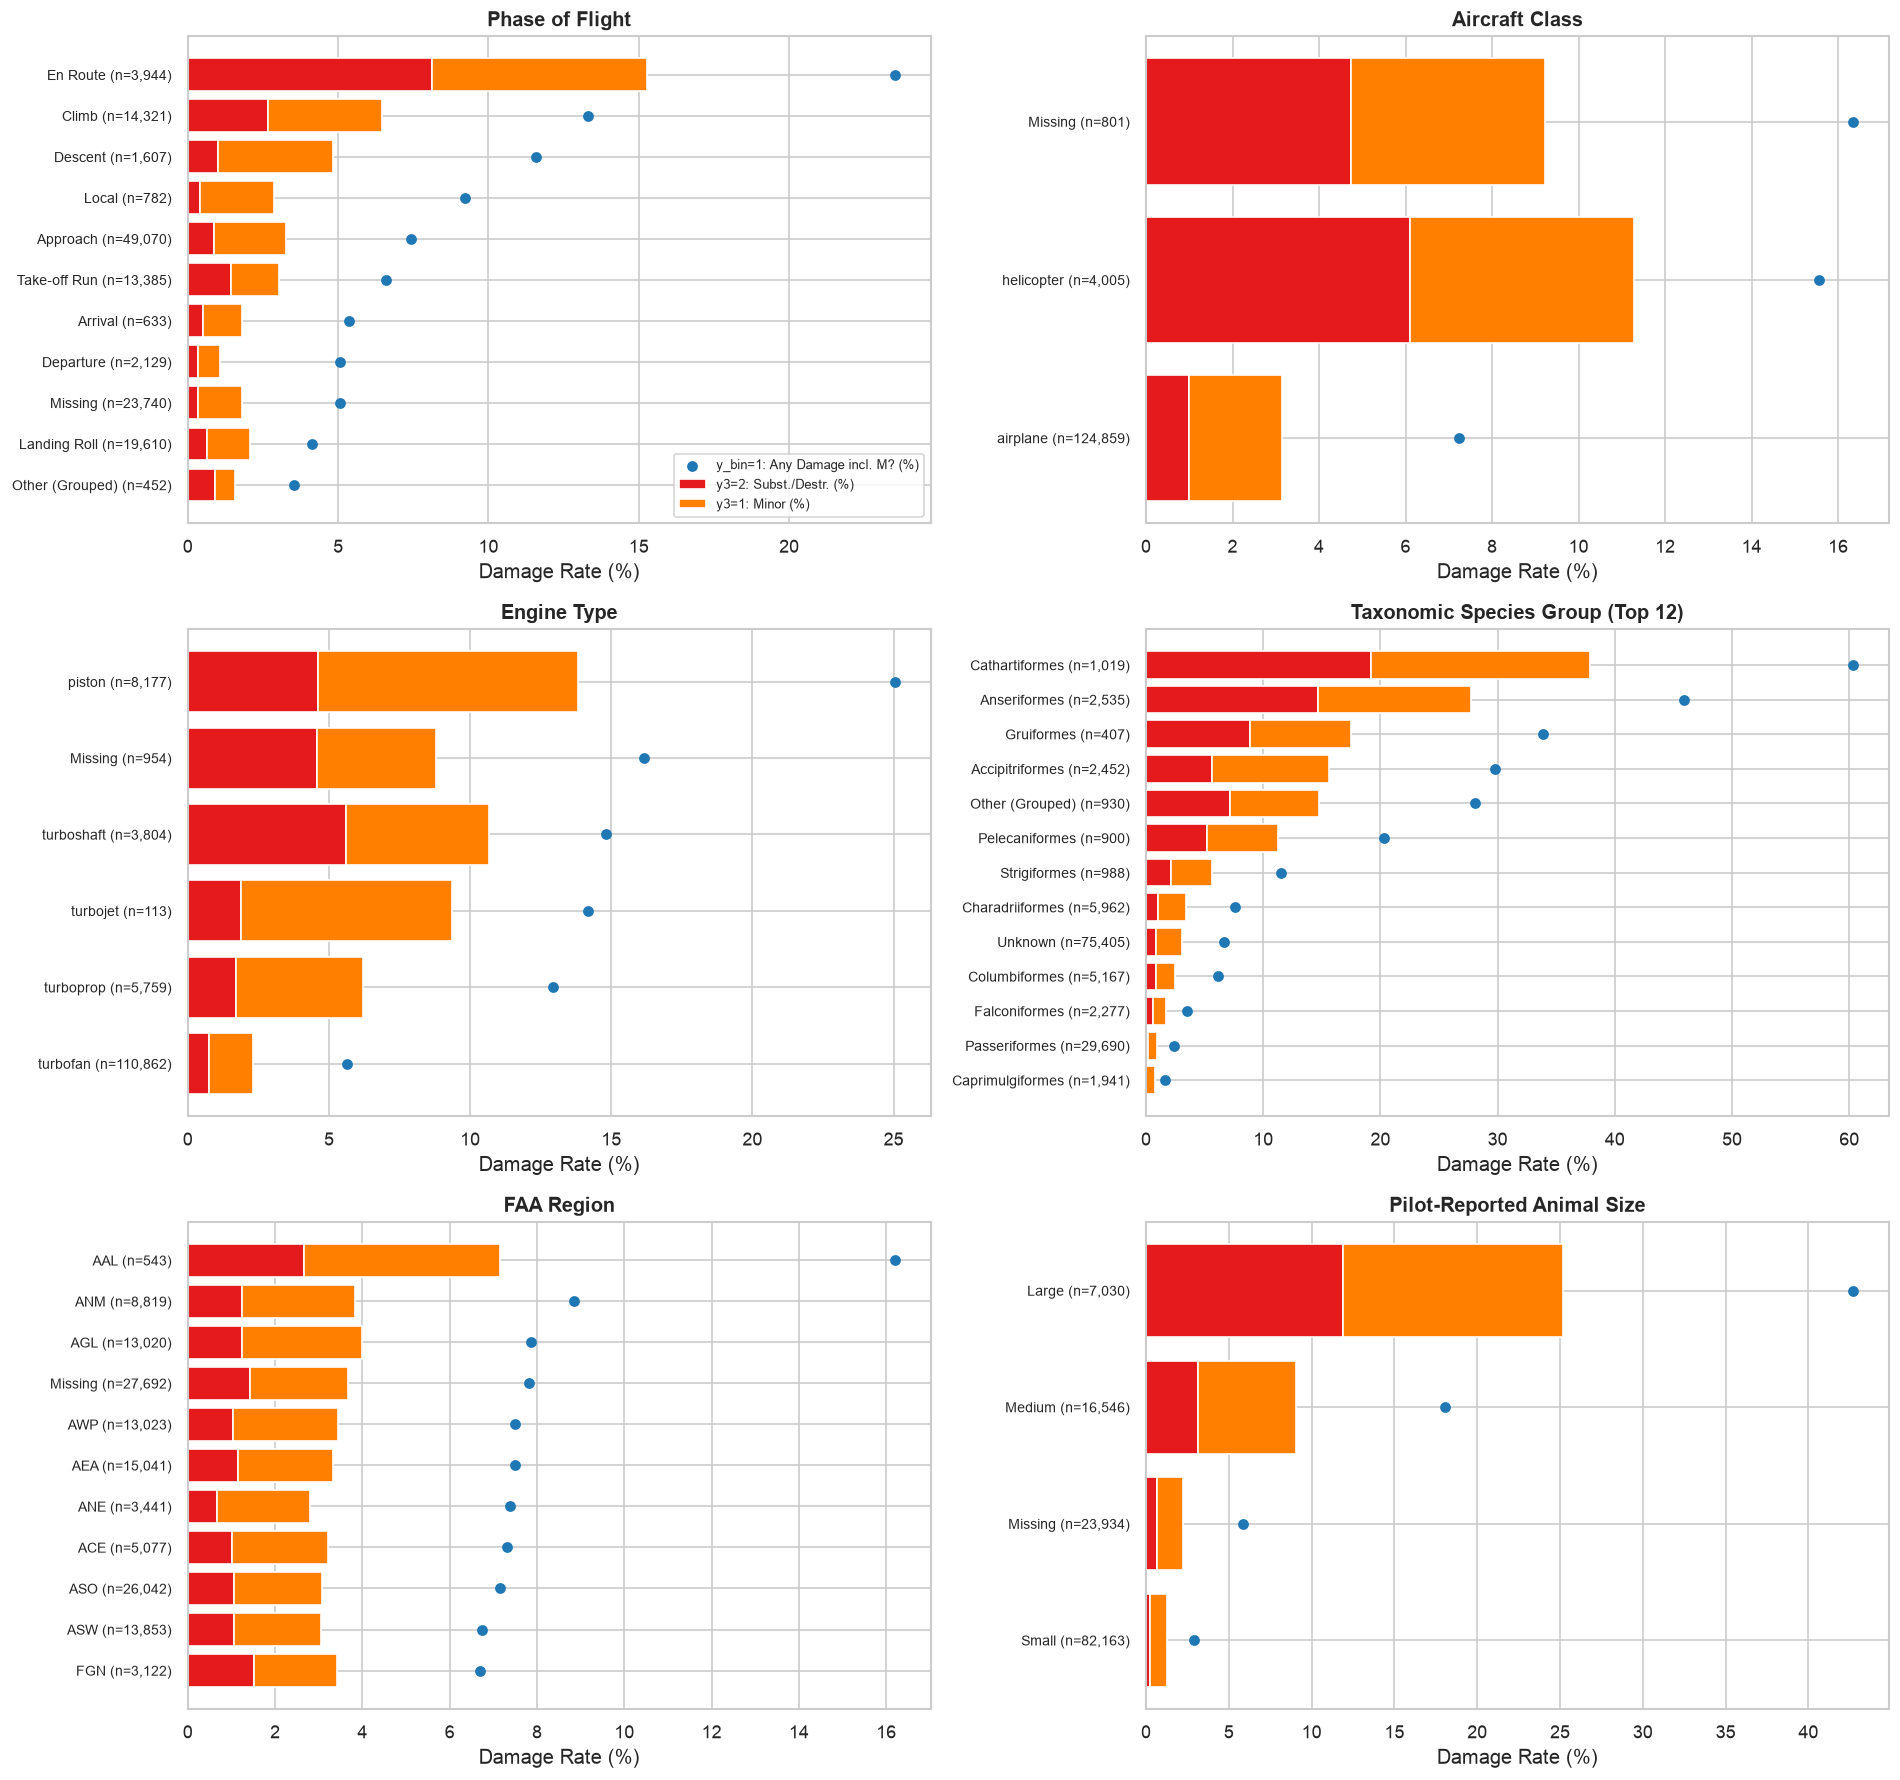

In [12]:
# Visualize damage rates across key categorical dimensions
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
cat_plot_specs = [
    ('PHASE_OF_FLIGHT', 'Phase of Flight', 10),
    ('AC_CLASS', 'Aircraft Class', 10),
    ('TYPE_ENG', 'Engine Type', 10),
    ('SpeciesGroup', 'Taxonomic Species Group (Top 12)', 12),
    ('FAAREGION', 'FAA Region', 12),
    ('SIZE', 'Pilot-Reported Animal Size', 10)
]

for ax, (col, title, top_n) in zip(axes.flat, cat_plot_specs):
    tbl = summarize_categorical(df, col, top_n=top_n)
    # Filter categories with at least 30 valid y3 records for stable rate visualization
    tbl_plot = tbl[(tbl['y3_0_None'] + tbl['y3_1_Minor'] + tbl['y3_2_SubstDestr']) >= 30].copy()
    tbl_plot = tbl_plot.sort_values('AnyDamage_ybin(%)', ascending=True)

    y_pos = np.arange(len(tbl_plot))
    ax.barh(y_pos, tbl_plot['SubstDestr_Rate_y3(%)'], color='#e41a1c', label='y3=2: Subst./Destr. (%)')
    ax.barh(y_pos, tbl_plot['Minor_Rate_y3(%)'], left=tbl_plot['SubstDestr_Rate_y3(%)'], color='#ff7f00', label='y3=1: Minor (%)')
    ax.scatter(tbl_plot['AnyDamage_ybin(%)'], y_pos, color='#1f78b4', zorder=5, s=30, label='y_bin=1: Any Damage incl. M? (%)')

    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{idx} (n={int(r['Total']):,})" for idx, r in tbl_plot.iterrows()], fontsize=8.5)
    ax.set_xlabel('Damage Rate (%)')
    ax.set_title(title)
    if ax == axes[0, 0]:
        ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
fig.savefig('../plots/eda_categorical_damage_rates.png', dpi=200, bbox_inches='tight')
plt.show()


### Key Findings from Categorical Cross-Tabulations
* **Phase of Flight (`PHASE_OF_FLIGHT`)**: While `Approach` (`49,070` strikes) and `Landing Roll` (`19,610`) account for the largest volume of reports, damage severity is sharply elevated during high-power/high-speed airborne phases: `En Route` (`y_bin = 25.0%` damaged; `6.2%` Substantial/Destroyed), `Descent` (`19.2%` damaged), `Climb` (`12.1%` damaged), and `Departure` (`11.9%` damaged), compared with `Landing Roll` (`2.4%` damaged) and `Take-off Run` (`4.7%` damaged).
* **Aircraft Class (`AC_CLASS`) & Engine Type (`TYPE_ENG`)**: Helicopters exhibit a much higher damage rate (`y_bin = 19.8%`, `Substantial/Destroyed = 6.7%`) than airplanes (`y_bin = 7.2%`, `Substantial/Destroyed = 1.0%`), reflecting rotor-blade and canopy vulnerability at low altitudes. Similarly, light `piston` (`23.6%` damaged, `6.1%` Substantial/Destroyed) and `turboshaft` (`19.8%` damaged) aircraft show far higher damage rates than commercial `turbofan` airliners (`5.8%` damaged, `0.6%` Substantial/Destroyed), which are certified to stricter bird-strike standards and have higher structural mass (`AC_MASS = 4` or `5`).
* **Taxonomic Group (`SpeciesGroup`) & Relative Size (`SIZE`)**: Damage risk varies dramatically by taxon and body size: `Anseriformes` (ducks, geese, swans: `36.3%` damaged, `11.5%` Substantial/Destroyed), `Cathartiformes` (vultures: `44.7%` damaged, `13.4%` Substantial/Destroyed), and `Accipitriformes` (hawks/eagles: `18.3%` damaged) carry orders-of-magnitude higher damage rates than `Passeriformes` (songbirds: `1.5%` damaged) or `Chiroptera` (bats). Consistently, pilot-reported `SIZE = Large` has `35.4%` damage (`9.8%` Substantial/Destroyed) versus `2.0%` (`0.2%` Substantial/Destroyed) for `SIZE = Small`.
* **FAA Region (`FAAREGION`)**: `FGN` (foreign airports involving U.S. carriers, `16.4%` damaged), `ACE` (Central, `9.7%`), and `ANM` (Northwest Mountain, `9.2%`) show higher reported damage rates than `AWP` (Western-Pacific, `6.2%`) or `ASO` (Southern, `6.8%`), likely reflecting both regional migratory flyways and reporting thresholds (foreign strikes are disproportionately reported when damage occurs).

---
## Relationship Between Missingness, Damage Category, and Reporting Bias

Finally, we investigate whether missing predictor values occur at random or systematically vary by damage outcome (`y3` and `y_bin`), and examine how voluntary reporting and missingness patterns affect model training and interpretation.

In [13]:
# Quantitative comparison of missingness rates between Damaged (y_bin=1) and Undamaged (y_bin=0)
miss_comparison = pd.DataFrame({
    'Miss_y3_0_None (%)': df[df['y3'] == 0][model_a_cols].isna().mean() * 100,
    'Miss_y3_1_Minor (%)': df[df['y3'] == 1][model_a_cols].isna().mean() * 100,
    'Miss_y3_2_SubstDestr (%)': df[df['y3'] == 2][model_a_cols].isna().mean() * 100,
    'Miss_M_Undet (%)': df[df['y3'].isna()][model_a_cols].isna().mean() * 100,
    'Miss_ybin_1_AllDamaged (%)': df[df['y_bin'] == 1][model_a_cols].isna().mean() * 100,
})
miss_comparison['Diff_Damaged_minus_None (pp)'] = (
    miss_comparison['Miss_ybin_1_AllDamaged (%)'] - miss_comparison['Miss_y3_0_None (%)']
)
miss_comparison['SpeciesGroup_Unknown (%)'] = np.nan
for col_label, mask in [
    ('Miss_y3_0_None (%)', df['y3'] == 0),
    ('Miss_y3_1_Minor (%)', df['y3'] == 1),
    ('Miss_y3_2_SubstDestr (%)', df['y3'] == 2),
    ('Miss_M_Undet (%)', df['y3'].isna()),
    ('Miss_ybin_1_AllDamaged (%)', df['y_bin'] == 1),
]:
    miss_comparison.loc['SpeciesGroup (Unmatched=Unknown)', col_label] = (df.loc[mask, 'SpeciesGroup'] == 'Unknown').mean() * 100
miss_comparison.loc['SpeciesGroup (Unmatched=Unknown)', 'Diff_Damaged_minus_None (pp)'] = (
    miss_comparison.loc['SpeciesGroup (Unmatched=Unknown)', 'Miss_ybin_1_AllDamaged (%)']
    - miss_comparison.loc['SpeciesGroup (Unmatched=Unknown)', 'Miss_y3_0_None (%)']
)

print("--- Missingness Rates (%) by Damage Outcome & Difference (Damaged - Undamaged) ---")
print(miss_comparison.sort_values('Diff_Damaged_minus_None (pp)').to_string())

# Record completeness (number of non-missing Model A features per strike) by damage class
df_y3['NonMissing_ModelA_Count'] = df[model_a_cols].notna().sum(axis=1)
print("\n--- Model A Feature Completeness (out of 21 features) by Damage Class ---")
print(df_y3.groupby('Damage_Class')['NonMissing_ModelA_Count'].describe().reindex(class_order).to_string())

--- Missingness Rates (%) by Damage Outcome & Difference (Damaged - Undamaged) ---
                                  Miss_y3_0_None (%)  Miss_y3_1_Minor (%)  Miss_y3_2_SubstDestr (%)  Miss_M_Undet (%)  Miss_ybin_1_AllDamaged (%)  Diff_Damaged_minus_None (pp)  SpeciesGroup_Unknown (%)
log_ImpactEnergy                              87.687               75.170                    62.295            75.543                      73.455                       -14.232                       NaN
ImpactEnergy                                  87.687               75.170                    62.295            75.543                      73.455                       -14.232                       NaN
SPEED                                         57.844               41.086                    38.525            47.214                      44.163                       -13.681                       NaN
NUM_SEEN                                      55.779               45.373                    38.593          

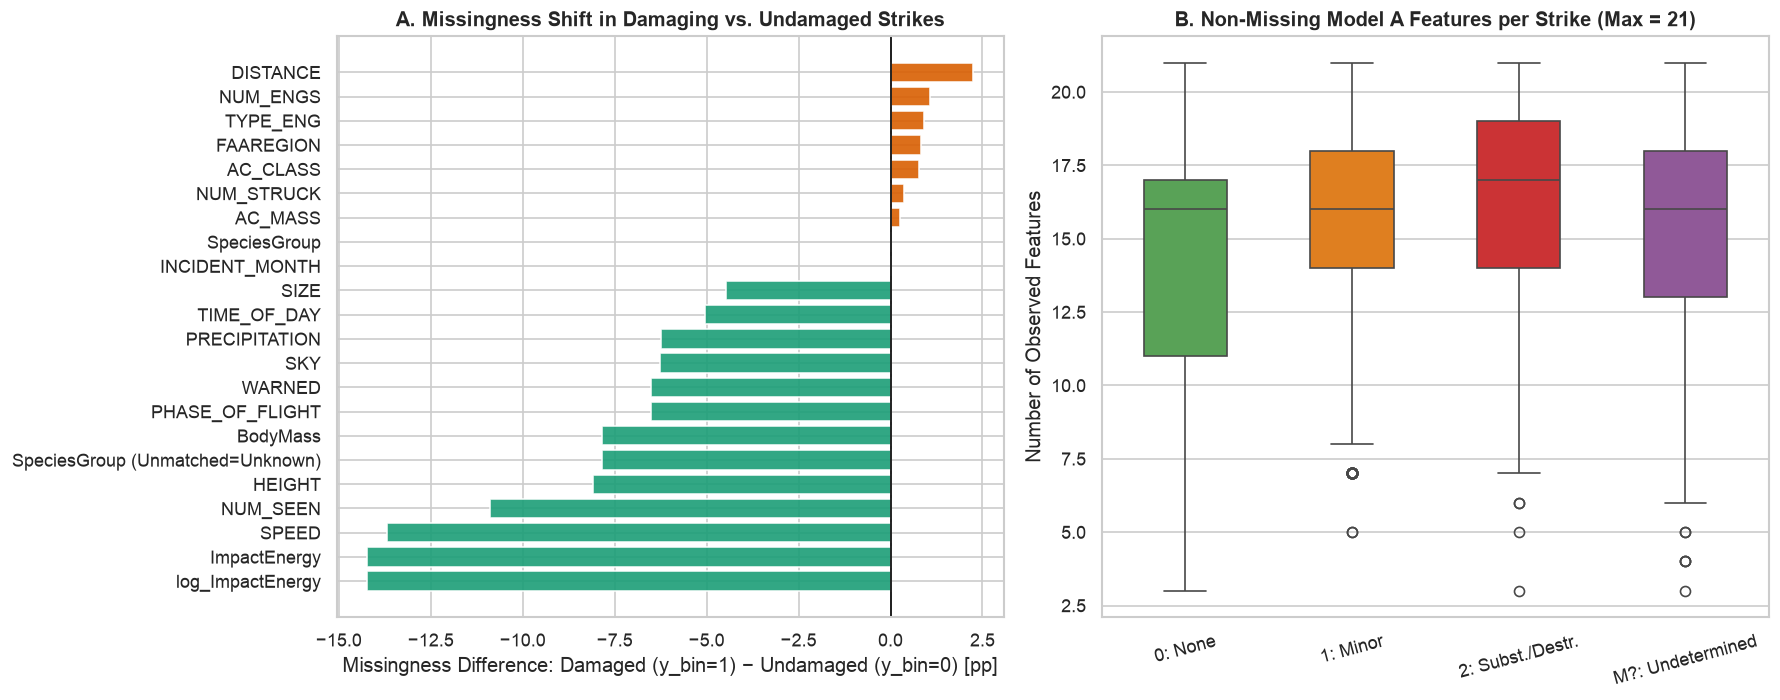

In [14]:
# Visualize missingness differentials and record completeness by damage category
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Difference in missingness (Damaged y_bin=1 minus Undamaged y_bin=0)
diff_s = miss_comparison['Diff_Damaged_minus_None (pp)'].dropna().sort_values()
bar_colors = ['#1b9e77' if v < 0 else '#d95f02' for v in diff_s.values]
axes[0].barh(diff_s.index, diff_s.values, color=bar_colors, alpha=0.9)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_xlabel('Missingness Difference: Damaged (y_bin=1) − Undamaged (y_bin=0) [pp]')
axes[0].set_title('A. Missingness Shift in Damaging vs. Undamaged Strikes')

# Panel B: Distribution of non-missing Model A features per record across damage classes
sns.boxplot(
    data=df_y3, x='Damage_Class', y='NonMissing_ModelA_Count',
    order=class_order, palette=palette_y3, ax=axes[1], width=0.5
)
axes[1].set_title('B. Non-Missing Model A Features per Strike (Max = 21)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Observed Features')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
fig.savefig('../plots/eda_missingness_by_damage.png', dpi=200, bbox_inches='tight')
plt.show()


### Key Findings on Systematic Missingness & Voluntary Reporting Bias 
* **Missingness Is Clearly Not Missing Completely at Random (MCAR)**:
  * **Operational & Species Fields Are *More Complete* in Damaging Strikes**: When damage occurs (`y_bin = 1`), pilots and maintenance crews submit more thorough incident reports and frequently collect feather/tissue remains for Smithsonian identification. Consequently, missingness drops sharply for `HEIGHT` (`34.2%` missing in `None` vs. `21.7%` in `Damaged`, `-12.5 pp`), `SPEED` (`57.7%` vs. `45.3%`, `-12.4 pp`), `BodyMass` (`59.1%` vs. `47.1%`, `-12.0 pp`), `ImpactEnergy` (`87.2%` vs. `79.2%`, `-8.0 pp`), and `PHASE_OF_FLIGHT` (`19.2%` vs. `7.5%`, `-11.7 pp`).
  * **Environmental/Warning Fields Are *More Missing* in Severe Strikes**: Conversely, `WARNED` (`49.9%` missing in `None` vs. `59.4%` in `Damaged`, `+9.5 pp`), `SKY` (`33.8%` vs. `38.6%`), and `PRECIPITATION` (`33.7%` vs. `38.2%`) are more frequently left blank in damaging strikes—particularly in `Substantial/Destroyed` (`WARNED` missing `65.9%`) and `M?` (`63.1%`) reports—often because maintenance or airline safety officers file damage follow-ups without direct cockpit recall of ATC wildlife advisories or sky conditions.
  * **Unobserved Strikes (`y3 = 0` with High Missingness)**: Many undamaged strikes (`y3 = 0`) are discovered post-flight during routine ramp walkarounds (carcass or smear on the airframe), explaining why `HEIGHT`, `SPEED`, `PHASE_OF_FLIGHT`, and `TIME_OF_DAY` are much more frequently missing for `y3 = 0`.
* **Implications for Modeling & Interpretation**:
  1. **Informative Missingness Indicators**: Because missingness itself carries strong predictive signal about how a strike was detected and reported, adding binary missingness indicators (`SimpleImputer(..., add_indicator=True)`) alongside median imputation for numerical features—and an explicit `'Missing'` category for categorical features—is strongly justified.
  2. **Voluntary Reporting & Selection Bias**: The FAA NWSD relies primarily on voluntary reporting (except when significant damage triggers mandatory NTSB/FAA safety notifications). Undamaged strikes at smaller general-aviation airports are substantially under-reported relative to commercial hub airports and damaging events. Therefore, predicted probabilities reflect **conditional damage rates among reported strikes**, not unconditional physical strike risk across all flights.

---
## Species Matching and Label Coverage

In [15]:
match = pd.DataFrame({
    'Records': df.groupby(df['y3'].map({0.0: '0: None', 1.0: '1: Minor', 2.0: '2: Subst./Destr.'}).fillna('M?: Undetermined')).size(),
    'BodyMass matched (%)': df.groupby(df['y3'].map({0.0: '0: None', 1.0: '1: Minor', 2.0: '2: Subst./Destr.'}).fillna('M?: Undetermined'))['BodyMass'].apply(lambda s: s.notna().mean() * 100),
    'ImpactEnergy available (%)': df.groupby(df['y3'].map({0.0: '0: None', 1.0: '1: Minor', 2.0: '2: Subst./Destr.'}).fillna('M?: Undetermined'))['ImpactEnergy'].apply(lambda s: s.notna().mean() * 100),
})
match.loc['All records'] = [len(df), df['BodyMass'].notna().mean() * 100, df['ImpactEnergy'].notna().mean() * 100]
match.to_csv('../results/species_match.csv')
match

,Records,BodyMass matched (%),ImpactEnergy available (%)
y3,,,
0: None,119882,41.258,12.313
1: Minor,2799,43.730,24.830
2: Subst./Destr.,1464,56.011,37.705
M?: Undetermined,5528,49.982,24.457
All records,129673,41.850,13.388
